# Exploratory Data Analysis (EDA) on Snitch_Fashion_Sales Dataset

## วิเคราะห์หาแนวโน้มยอดขายและกำไรรายไตรมาส โดยเน้นไตรมาสล่าสุดในข้อมูล

In [ ]:
# Load libraries
import pandas as pd # DataFrame
import seaborn as sb # graph
import matplotlib.pyplot as plt # Plot
import seaborn as sns

# Data Aquistion

In [ ]:
#from kaggle: https://www.kaggle.com/datasets/nayakganesh007/snitch-clothing-sales

In [ ]:
# Download dataset from Kaggle (kagglehub)
try:
    import kagglehub
except ImportError:
    %pip install -q kagglehub
    import kagglehub

import os, glob

path = kagglehub.dataset_download("nayakganesh007/snitch-clothing-sales")
print("Path to dataset files:", path)

DATA_PATH = glob.glob(os.path.join(path, "**", "Snitch_Fashion_Sales_Uncleaned.csv"), recursive=True)[0]
print("CSV file:", DATA_PATH)

[sandbox stub] using local copy of nayakganesh007/snitch-clothing-sales
Path to dataset files: /tmp/kdata
CSV file: /tmp/kdata/Snitch_Fashion_Sales_Uncleaned.csv


In [ ]:
# Read data
Snitch_data = pd.read_csv(DATA_PATH)

In [ ]:
Snitch_data.head(10)

,Order_ID,Customer_Name,Product_Category,Product_Name,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Order_Date,City,Segment,Profit
0,1000,Brian Thompson,Jeans,Slim Fit Jeans,NaN,842.00,0.60,0.00,2025-02-27,Delhi,B2C,2137.45
1,1001,Shaun Ross,Jeans,Slim Fit Jeans,1.0,NaN,NaN,0.00,2025-07-15,Ahmedabad,NaN,1588.15
2,1002,Sarah Snyder,Jackets,Puffer Coat,1.0,637.82,NaN,0.00,02-01-2025,Mumbai,B2B,-158.03
3,1003,Jay Briggs,Shoes,Loafers,2.0,2962.27,NaN,0.00,18-06-2025,bengaluru,B2B,2296.50
4,1004,Maria Blake,Accessories,Belts,1.0,2881.07,0.27,2103.18,NaN,hyderbad,NaN,63.66
5,1005,Samuel Miller,T-Shirts,Crop Top,NaN,NaN,NaN,0.00,2023-12-05,Mumbai,B2B,1477.73
6,1006,John Mclean,Jeans,Boyfriend Jeans,1.0,2060.85,NaN,0.00,2024-04-02,Ahmedabad,B2B,198.36
7,1007,Dr. Kathryn Bass PhD,Dresses,Casual Midi,NaN,3669.56,NaN,0.00,NaN,Bangalore,B2C,2490.01
8,1008,Marie Fisher,Accessories,Sunglasses,NaN,NaN,NaN,0.00,NaN,Ahmedabad,B2C,-886.80
9,1009,Dale Perry,T-Shirts,Oversized T-shirt,5.0,NaN,NaN,0.00,2025-07-20,Bangalore,B2B,-972.73


In [ ]:
Snitch_data.shape

(2500, 12)

The dataset has 2500 rows and 12 columns



* Data Description

* Order_ID : Unique ID for each sale

* Customer_Name : Name of the customer

* Product_Category : Clothing category (e.g., T-Shirts, Jeans — includes typos)

* Product_Name : Specific product sold

* Units_Sold : Quantity sold

* Unit_Price : Price per unit

* Discount_% : Discount applied

* Sales_Amount : Total revenue after discount

* Order_Date : Order date

* City : Indian city

* Segment : Market segment

* Profit : Profit made on the sale
* List item



# Data Preparation

In [ ]:
Snitch_cleaned = Snitch_data.iloc[:,1:]

In [ ]:
Snitch_cleaned.head()

,Customer_Name,Product_Category,Product_Name,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Order_Date,City,Segment,Profit
0,Brian Thompson,Jeans,Slim Fit Jeans,NaN,842.00,0.60,0.00,2025-02-27,Delhi,B2C,2137.45
1,Shaun Ross,Jeans,Slim Fit Jeans,1.0,NaN,NaN,0.00,2025-07-15,Ahmedabad,NaN,1588.15
2,Sarah Snyder,Jackets,Puffer Coat,1.0,637.82,NaN,0.00,02-01-2025,Mumbai,B2B,-158.03
3,Jay Briggs,Shoes,Loafers,2.0,2962.27,NaN,0.00,18-06-2025,bengaluru,B2B,2296.50
4,Maria Blake,Accessories,Belts,1.0,2881.07,0.27,2103.18,NaN,hyderbad,NaN,63.66


# Checking and handling duplicate data

In [ ]:
Snitch_cleaned.duplicated().sum()

np.int64(0)

In [ ]:
Snitch_cleaned[Snitch_cleaned.duplicated()]

,Customer_Name,Product_Category,Product_Name,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Order_Date,City,Segment,Profit


In [ ]:
Snitch_cleaned.describe()

,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Profit
count,1194.000000,1290.000000,849.000000,2500.000000,2500.000000
mean,1.940536,2691.715527,0.646466,126.756252,981.569032
std,2.625680,1320.448967,0.380331,1464.944525,1159.159244
min,-2.000000,400.210000,0.000000,-7518.330000,-992.610000
25%,0.000000,1526.195000,0.300000,0.000000,-19.670000
50%,2.000000,2685.985000,0.650000,0.000000,947.885000
75%,4.000000,3824.347500,0.980000,0.000000,1993.515000
max,6.000000,4998.910000,1.300000,29180.680000,2997.110000


In [ ]:
# Drop duplicated values
Snitch_dropdup = Snitch_cleaned.drop_duplicates()

In [ ]:
Snitch_dropdup

,Customer_Name,Product_Category,Product_Name,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Order_Date,City,Segment,Profit
0,Brian Thompson,Jeans,Slim Fit Jeans,NaN,842.00,0.60,0.00,2025-02-27,Delhi,B2C,2137.45
1,Shaun Ross,Jeans,Slim Fit Jeans,1.0,NaN,NaN,0.00,2025-07-15,Ahmedabad,NaN,1588.15
2,Sarah Snyder,Jackets,Puffer Coat,1.0,637.82,NaN,0.00,02-01-2025,Mumbai,B2B,-158.03
3,Jay Briggs,Shoes,Loafers,2.0,2962.27,NaN,0.00,18-06-2025,bengaluru,B2B,2296.50
4,Maria Blake,Accessories,Belts,1.0,2881.07,0.27,2103.18,NaN,hyderbad,NaN,63.66
...,...,...,...,...,...,...,...,...,...,...,...
2495,Allen Williams,T-Shirts,Oversized T-shirt,NaN,848.79,NaN,0.00,NaN,Mumbai,NaN,2259.00
2496,Jonathan Hill,Shoes,Loafers,4.0,NaN,NaN,0.00,2024-03-10,Hyderabad,B2B,2232.98
2497,Alejandro Cochran,Jackets,Bomber Jacket,NaN,3389.24,1.06,0.00,NaN,Ahmedabad,B2C,1955.31
2498,Angela Adkins,Jeans,Straight Cut,5.0,3844.19,NaN,0.00,24-07-2024,Hyd,NaN,2967.00


In [ ]:
n_dup = Snitch_cleaned.duplicated().sum()
print(f"{len(Snitch_cleaned)} - {n_dup} = {len(Snitch_dropdup)} rows")

2500 - 0 = 2500 rows


# Checking and handling inconsistent Datatypes

In [ ]:
# Find unique values in column 'class'
Snitch_dropdup['City'].unique()

array(['Delhi', 'Ahmedabad', 'Mumbai', 'bengaluru', 'hyderbad',
       'Bangalore', 'Pune', 'Hyd', 'Hyderabad'], dtype=object)

In [ ]:
print(Snitch_dropdup['Order_Date'].unique())

['2025-02-27' '2025-07-15' '02-01-2025' ... '2024-08-15' '2023-12-31'
 '25-11-2024']


In [ ]:
print(Snitch_dropdup['Product_Category'].unique())


['Jeans' 'Jackets' 'Shoes' 'Accessories' 'T-Shirts' 'Dresses']


In [ ]:
print(Snitch_dropdup['Product_Name'].unique())

['Slim Fit Jeans' 'Puffer Coat' 'Loafers' 'Belts' 'Crop Top'
 'Boyfriend Jeans' 'Casual Midi' 'Sunglasses' 'Oversized T-shirt'
 'Straight Cut' 'Sneakers' 'Maxi Dress' 'Wrap Dress' 'Slip-ons'
 'Classic Tee' 'Bomber Jacket' 'Graphic Tee' 'Boots' 'Denim Jacket'
 'Bodycon' 'Ripped Denim' 'Watches' 'Leather Jacket' 'Caps']


### column 'City' has inconsistene data. ('hyd' represents 'Hyderabad')

In [ ]:

FILE_PATH = DATA_PATH  # ได้จากเซลล์ดาวน์โหลด Kaggle ด้านบน
DATE_COLUMN = 'Order_Date'


EXCLUDE_COLUMN_FOR_DUPLICATES = ['Order_ID']

CITY_MAPPING = {
    'hyd': 'Hyderabad',
    'hyderabad': 'Hyderabad',
    'bengaluru': 'Bengaluru',
    'bangalore': 'Bengaluru',
    'mumbai': 'Mumbai',
    'delhi': 'Delhi',
    'pune': 'Pune',
    'ahmedabad': 'Ahmedabad',
}

def clean_text_data(df):
    """ทำความสะอาดคอลัมน์ City และ Product_Category ให้เป็นมาตรฐาน"""


    df_clean = df.copy()

    # City
    df_clean['City'] = df_clean['City'].str.lower().str.strip()
    df_clean['City'] = df_clean['City'].replace(CITY_MAPPING)
    df_clean['City'] = df_clean['City'].str.title()


    return df_clean

if 'Snitch_dropdup' in locals() or 'Snitch_dropdup' in globals():
    # กำหนดผลลัพธ์กลับไปที่ Snitch_dropdup
    Snitch_dropdup = clean_text_data(Snitch_dropdup)

    print("\n--- ตรวจสอบ 5 แถวแรกของ Snitch_dropdup หลังทำความสะอาด Text ---")
    print(Snitch_dropdup[['Order_Date', 'City']].head())
    print("-" * 50)

    # ตรวจสอบว่า Warning หายไปและข้อมูลสะอาดแล้ว
    print("Unique Cities ที่เหลือ:")
    print(Snitch_dropdup['City'].unique())
    print(f" จำนวนแถวสุดท้ายของ Snitch_dropdup คือ: {len(Snitch_dropdup)}")
else:
    print(" ข้อผิดพลาด: ไม่พบตัวแปร Snitch_dropdup กรุณารันโค้ด clean_standardize_and_sort_data ก่อน")


--- ตรวจสอบ 5 แถวแรกของ Snitch_dropdup หลังทำความสะอาด Text ---
   Order_Date       City
0  2025-02-27      Delhi
1  2025-07-15  Ahmedabad
2  02-01-2025     Mumbai
3  18-06-2025  Bengaluru
4         NaN   Hyderbad
--------------------------------------------------
Unique Cities ที่เหลือ:
['Delhi' 'Ahmedabad' 'Mumbai' 'Bengaluru' 'Hyderbad' 'Pune' 'Hyderabad']
 จำนวนแถวสุดท้ายของ Snitch_dropdup คือ: 2500


### column 'Order_Date' has inconsistent data (มี 3 รูปแบบ)

* `yyyy-mm-dd` เช่น `2025-02-27`
* `yyyy/mm/dd` เช่น `2024/08/22`
* `dd-mm-yyyy` เช่น `02-01-2025` (= **2 ม.ค. 2025**) ตรวจแล้วว่าเป็นวัน-เดือน-ปี เพราะพบค่าในตำแหน่งแรกที่มากกว่า 12 แต่ไม่เคยพบค่าในตำแหน่งที่สองที่มากกว่า 12

จึงต้องแปลง **แยกตามรูปแบบ** ห้ามใช้ `format='mixed'` เพราะจะอ่าน `02-01-2025` เป็น 1 ก.พ. และอ่าน `12-07-2025` เป็น 7 ธ.ค. 2025 (ทำให้เกิดไตรมาสปลอมที่ไม่มีอยู่จริง)

In [ ]:

FILE_PATH = DATA_PATH  # ได้จากเซลล์ดาวน์โหลด Kaggle ด้านบน
DATE_COLUMN = 'Order_Date'


EXCLUDE_COLUMN_FOR_DUPLICATES = ['Order_ID']

def clean_standardize_and_sort_data(file_path, date_col_name, output_format='%d-%m-%Y'):
    # อ่านไฟล์ CSV
    try:
        df = pd.read_csv(file_path)
        print(f" อ่านไฟล์สำเร็จ: {file_path}. จำนวนแถวเริ่มต้น: {len(df)}")
    except FileNotFoundError:
        print(f" ข้อผิดพลาด: ไม่พบไฟล์ CSV ที่พาธนี้: {file_path}")
        return None

    # สร้าง Subset สำหรับตรวจสอบความซ้ำซ้อน: ใช้ทุกคอลัมน์ยกเว้นคอลัมน์ที่ถูกยกเว้น
    columns_to_check = [col for col in df.columns if col not in EXCLUDE_COLUMN_FOR_DUPLICATES]

    # ลบแถวที่ซ้ำกัน เผื่อเอาไว้
    df_final_clean = df.drop_duplicates(
        subset=columns_to_check,
        keep='first'
    ).reset_index(drop=True)

    # แปลงข้อมูลวันที่ให้เป็น Datetime Object มาตรฐาน (แยกตามรูปแบบ ไม่ใช้ format='mixed')
    date_str = df_final_clean[date_col_name].astype('string').str.strip()
    iso_dt   = pd.to_datetime(date_str, format='%Y-%m-%d', errors='coerce')  # yyyy-mm-dd
    slash_dt = pd.to_datetime(date_str, format='%Y/%m/%d', errors='coerce')  # yyyy/mm/dd
    dmy_dt   = pd.to_datetime(date_str, format='%d-%m-%Y', errors='coerce')  # dd-mm-yyyy
    df_final_clean['Date_Standard'] = iso_dt.fillna(slash_dt).fillna(dmy_dt)

    # ตรวจว่ามีวันที่ที่แปลงไม่ได้ (ไม่ใช่ค่าว่างเดิม) หรือไม่ ควรเป็น 0
    n_unparsed = (date_str.notna() & df_final_clean['Date_Standard'].isna()).sum()
    print(f" วันที่แปลงรูปแบบไม่ได้: {n_unparsed} แถว | วันที่ว่างในไฟล์ต้นฉบับ: {date_str.isna().sum()} แถว")

    # จัดเรียงข้อมูลตามวันที่ที่ทำความสะอาดแล้ว
    df_sorted = df_final_clean.sort_values(
        by='Date_Standard',
        ascending=True,
        na_position='last'
    ).reset_index(drop=True)

    # แปลงคอลัมน์ Order_Date_Cleaned กลับเป็น String
    df_sorted[date_col_name] = df_sorted['Date_Standard'].dt.strftime(output_format)
    df_sorted[date_col_name] = df_sorted[date_col_name].replace({'NaT': ''})

    # ลบคอลัมน์ Date_Standard
    df_sorted = df_sorted.drop(columns=['Date_Standard'])

    return df_sorted

Snitch_dropdup = clean_standardize_and_sort_data(FILE_PATH, DATE_COLUMN)

if Snitch_dropdup is not None:
    print("\n--- 10 แถวแรกของ DataFrame ที่ถูกจัดเรียงและทำความสะอาดแล้ว ---")
    print(Snitch_dropdup[[DATE_COLUMN, 'Sales_Amount']].head(10))
    print("-" * 50)
    # ตรวจสอบจำนวนแถวสุดท้าย
    print(f" จำนวนแถวสุดท้ายของ Snitch_dropdup คือ: {len(Snitch_dropdup)}")

 อ่านไฟล์สำเร็จ: /tmp/kdata/Snitch_Fashion_Sales_Uncleaned.csv. จำนวนแถวเริ่มต้น: 2500
 วันที่แปลงรูปแบบไม่ได้: 0 แถว | วันที่ว่างในไฟล์ต้นฉบับ: 606 แถว

--- 10 แถวแรกของ DataFrame ที่ถูกจัดเรียงและทำความสะอาดแล้ว ---
   Order_Date  Sales_Amount
0  23-07-2023           0.0
1  23-07-2023           0.0
2  25-07-2023           0.0
3  25-07-2023           0.0
4  26-07-2023           0.0
5  26-07-2023           0.0
6  26-07-2023           0.0
7  27-07-2023           0.0
8  28-07-2023           0.0
9  28-07-2023           0.0
--------------------------------------------------
 จำนวนแถวสุดท้ายของ Snitch_dropdup คือ: 2500


In [ ]:
Snitch_dropdup

,Order_ID,Customer_Name,Product_Category,Product_Name,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Order_Date,City,Segment,Profit
0,2889,Jasmine Mcgee,Shoes,Loafers,5.0,NaN,NaN,0.0,23-07-2023,Hyd,NaN,1874.28
1,1248,Edward Morgan,Accessories,Watches,NaN,NaN,1.24,0.0,23-07-2023,Mumbai,B2B,397.41
2,1820,John Bailey,T-Shirts,Graphic Tee,5.0,1965.04,NaN,0.0,25-07-2023,Pune,NaN,20.89
3,1389,Barbara Jones,Dresses,Wrap Dress,2.0,2742.38,NaN,0.0,25-07-2023,Ahmedabad,NaN,1987.46
4,3450,Mario Smith,T-Shirts,Classic Tee,NaN,NaN,0.89,0.0,26-07-2023,Mumbai,NaN,1339.05
...,...,...,...,...,...,...,...,...,...,...,...,...
2495,3492,Jonathan Meadows,Jeans,Ripped Denim,NaN,3084.73,0.86,0.0,NaN,Mumbai,NaN,2534.32
2496,3494,Ryan West,Jeans,Slim Fit Jeans,0.0,NaN,NaN,0.0,NaN,Ahmedabad,NaN,-219.82
2497,3495,Allen Williams,T-Shirts,Oversized T-shirt,NaN,848.79,NaN,0.0,NaN,Mumbai,NaN,2259.00
2498,3497,Alejandro Cochran,Jackets,Bomber Jacket,NaN,3389.24,1.06,0.0,NaN,Ahmedabad,B2C,1955.31


### There is no inconsistent values.

# Checking and handling missing data

In [ ]:
# Check for missing values
Snitch_dropdup.isnull()

,Order_ID,Customer_Name,Product_Category,Product_Name,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Order_Date,City,Segment,Profit
0,False,False,False,False,False,True,True,False,False,False,True,False
1,False,False,False,False,True,True,False,False,False,False,False,False
2,False,False,False,False,False,False,True,False,False,False,True,False
3,False,False,False,False,False,False,True,False,False,False,True,False
4,False,False,False,False,True,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
2495,False,False,False,False,True,False,False,False,True,False,True,False
2496,False,False,False,False,False,True,True,False,True,False,True,False
2497,False,False,False,False,True,False,True,False,True,False,True,False
2498,False,False,False,False,True,False,False,False,True,False,False,False


In [ ]:
# Check number of missing values
Snitch_dropdup.isnull().sum()

Order_ID               0
Customer_Name          0
Product_Category       0
Product_Name           0
Units_Sold          1306
Unit_Price          1210
Discount_%          1651
Sales_Amount           0
Order_Date           606
City                   0
Segment              821
Profit                 0
dtype: int64

In [ ]:
Snitch_dropdup.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2500 non-null   int64  
 1   Customer_Name     2500 non-null   object 
 2   Product_Category  2500 non-null   object 
 3   Product_Name      2500 non-null   object 
 4   Units_Sold        1194 non-null   float64
 5   Unit_Price        1290 non-null   float64
 6   Discount_%        849 non-null    float64
 7   Sales_Amount      2500 non-null   float64
 8   Order_Date        1894 non-null   object 
 9   City              2500 non-null   object 
 10  Segment           1679 non-null   object 
 11  Profit            2500 non-null   float64
dtypes: float64(5), int64(1), object(6)
memory usage: 234.5+ KB


In [ ]:
Snitch_dropdup['Units_Sold'].mean()

np.float64(1.940536013400335)

In [ ]:
# Unit_Sold: แทนที่ด้วย Median
Snitch_fillmissing_Units_Sold = Snitch_dropdup.fillna({'Units_Sold':Snitch_dropdup['Units_Sold'].mean()})

In [ ]:
# แก้ไข Units_Sold ที่เป็นค่าลบ โดยแปลงให้เป็น 0
Snitch_fillmissing_Units_Sold.loc[Snitch_fillmissing_Units_Sold['Units_Sold'] < 0, 'Units_Sold'] = 0

In [ ]:
Snitch_fillmissing_Units_Sold.isnull().sum()

Order_ID               0
Customer_Name          0
Product_Category       0
Product_Name           0
Units_Sold             0
Unit_Price          1210
Discount_%          1651
Sales_Amount           0
Order_Date           606
City                   0
Segment              821
Profit                 0
dtype: int64

In [ ]:
Snitch_dropdup['Unit_Price'].mean()

np.float64(2691.7155271317833)

In [ ]:
# Unit_Price: แทนที่ด้วย Median
Snitch_fillmissing_Unit_Price = Snitch_fillmissing_Units_Sold.fillna({'Unit_Price':Snitch_fillmissing_Units_Sold['Unit_Price'].mean()})

In [ ]:
Snitch_fillmissing_Unit_Price.isnull().sum()

Order_ID               0
Customer_Name          0
Product_Category       0
Product_Name           0
Units_Sold             0
Unit_Price             0
Discount_%          1651
Sales_Amount           0
Order_Date           606
City                   0
Segment              821
Profit                 0
dtype: int64

In [ ]:
# จำกัดค่า Discount_% ไม่ให้เกิน 1.00 (100%)
Snitch_fillmissing_Unit_Price.loc[Snitch_fillmissing_Unit_Price['Discount_%'] > 1.00, 'Discount_%'] = 1.00

In [ ]:
# Discount_%: แทนที่ด้วย 0
Snitch_fillmissing_Unit_Price['Discount_%'] = Snitch_fillmissing_Unit_Price['Discount_%'].fillna(0)

In [ ]:
Snitch_fillmissing_Unit_Price.isnull().sum()

Order_ID              0
Customer_Name         0
Product_Category      0
Product_Name          0
Units_Sold            0
Unit_Price            0
Discount_%            0
Sales_Amount          0
Order_Date          606
City                  0
Segment             821
Profit                0
dtype: int64

In [ ]:
# แทนที่ค่าฐานนิยม (mode_segment) ด้วยค่า 'Unknown'
unknown_segment_value = 'Unknown'

In [ ]:
Snitch_fillmissing_Segment = Snitch_fillmissing_Unit_Price.fillna({'Segment': unknown_segment_value})

In [ ]:
Snitch_fillmissing_Segment.isnull().sum()

Order_ID              0
Customer_Name         0
Product_Category      0
Product_Name          0
Units_Sold            0
Unit_Price            0
Discount_%            0
Sales_Amount          0
Order_Date          606
City                  0
Segment               0
Profit                0
dtype: int64

In [ ]:
Snitch_fillmissing_Date = Snitch_fillmissing_Segment.copy()

In [ ]:
# Order_Date: ไม่เติมค่าว่าง (ไม่ใช้ Forward Fill เพราะจะสร้างวันที่ปลอมให้ออเดอร์ที่ไม่มีวันที่)
# แถวที่ไม่มีวันที่จะถูกแยกออกจากการวิเคราะห์รายไตรมาสโดยตั้งใจ
Snitch_fillmissing_Date = Snitch_fillmissing_Date.copy()

In [ ]:
Snitch_fillmissing_Date.isnull().sum()

Order_ID              0
Customer_Name         0
Product_Category      0
Product_Name          0
Units_Sold            0
Unit_Price            0
Discount_%            0
Sales_Amount          0
Order_Date          606
City                  0
Segment               0
Profit                0
dtype: int64

### ไม่มี missing data ยกเว้น `Order_Date` ที่ตั้งใจเก็บเป็นค่าว่างไว้ (ไม่เติม) และจะไม่นับเข้าไตรมาสใดเลย

# Checking and Handling Outliers

In [ ]:
# แปลง Order_Date (dd-mm-yyyy จากขั้นตอนก่อนหน้า) กลับเป็น datetime โดยระบุรูปแบบให้ชัดเจน
Snitch_dropdup['Order_Date'] = pd.to_datetime(
    Snitch_dropdup['Order_Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [ ]:
# สร้างคอลัมน์ Quarter/Year (เช่น 2024-Q1)
Snitch_dropdup['Quarter'] = Snitch_dropdup['Order_Date'].dt.to_period('Q').astype(str)

In [ ]:
# รวมยอดขาย Total_Sales ตาม Quarter (เฉพาะแถวที่มีวันที่)
dated = Snitch_dropdup.dropna(subset=['Order_Date'])
undated = Snitch_dropdup[Snitch_dropdup['Order_Date'].isna()]
print(f"แถวที่มีวันที่: {len(dated)} | ไม่มีวันที่ (ไม่นับเข้าไตรมาส): {len(undated)} แถว, Sales {undated['Sales_Amount'].sum():,.2f}")
print(f"ช่วงวันที่: {dated['Order_Date'].min().date()} ถึง {dated['Order_Date'].max().date()}")

quarterly_sales = dated.groupby('Quarter')['Sales_Amount'].sum().reset_index()
quarterly_sales.rename(columns={'Sales_Amount': 'Total_Sales'}, inplace=True)

แถวที่มีวันที่: 1894 | ไม่มีวันที่ (ไม่นับเข้าไตรมาส): 606 แถว, Sales 64,069.86
ช่วงวันที่: 2023-07-23 ถึง 2025-07-22


In [ ]:
quarterly_sales.head(15)

,Quarter,Total_Sales
0,2023Q3,21102.49
1,2023Q4,4629.33
2,2024Q1,-937.93
3,2024Q2,-1002.61
4,2024Q3,70311.83
5,2024Q4,28943.64
6,2025Q1,52840.38
7,2025Q2,33549.09
8,2025Q3,43384.55


In [ ]:
Q1 = quarterly_sales['Total_Sales'].quantile(0.25)
Q3 = quarterly_sales['Total_Sales'].quantile(0.75)

In [ ]:
IQR = Q3 - Q1

In [ ]:
# คำนวณขอบเขตการตรวจจับ Outlier
# High outliers > Q3 + (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

In [ ]:
# Low outliers < Q1 - (1.5 * IQR)
lower_bound = Q1 - (1.5 * IQR)

In [ ]:
print(f"Q1 (25%): {Q1:,.2f}")
print(f"Q3 (75%): {Q3:,.2f}")
print(f"IQR (Q3 - Q1): {IQR:,.2f}")
print("-" * 40)
print(f"Lower Bound (ต่ำกว่านี้คือ Outlier): {lower_bound:,.2f}")
print(f"Upper Bound (สูงกว่านี้คือ Outlier): {upper_bound:,.2f}")

Q1 (25%): 4,629.33
Q3 (75%): 43,384.55
IQR (Q3 - Q1): 38,755.22
----------------------------------------
Lower Bound (ต่ำกว่านี้คือ Outlier): -53,503.50
Upper Bound (สูงกว่านี้คือ Outlier): 101,517.38


In [ ]:
# หา Outliers
outliers = quarterly_sales[
    (quarterly_sales['Total_Sales'] < lower_bound) |   # Low Outliers
    (quarterly_sales['Total_Sales'] > upper_bound)     # High Outliers
    ]

In [ ]:
# จำกัดค่า Profit
# กำหนดให้ค่าที่ต่ำกว่า Lower Bound เท่ากับ Lower Bound
Snitch_dropdup.loc[Snitch_dropdup['Profit'] < lower_bound, 'Profit'] = lower_bound

# กำหนดให้ค่าที่สูงกว่า Upper Bound เท่ากับ Upper Bound
Snitch_dropdup.loc[Snitch_dropdup['Profit'] > upper_bound, 'Profit'] = upper_bound

In [ ]:
# กรองหาแถวที่ขาดทุน
loss_transactions = Snitch_dropdup[Snitch_dropdup['Profit'] < 0]

#  วิเคราะห์การขาดทุนตาม Segment (กลุ่มลูกค้า)
print("--- 1.1 การขาดทุนตามกลุ่มลูกค้า ---")
loss_by_segment = loss_transactions.groupby('Segment')['Profit'].sum().apply('{:,.2f}'.format)
print(loss_by_segment)

#  วิเคราะห์การขาดทุนตาม Discount_% (ช่วงส่วนลด)
print("\n--- 1.2 การขาดทุนที่เกิดจากส่วนลดสูงสุด ---")

# ดูว่าการขาดทุนส่วนใหญ่มาจากรายการที่มีส่วนลดเท่าไหร่
loss_by_discount = loss_transactions.groupby('Discount_%')['Profit'].sum().sort_values().head(5)
print(loss_by_discount.apply('{:,.2f}'.format))

--- 1.1 การขาดทุนตามกลุ่มลูกค้า ---
Segment
B2B    -102,686.62
B2C    -105,547.30
Name: Profit, dtype: object

--- 1.2 การขาดทุนที่เกิดจากส่วนลดสูงสุด ---
Discount_%
0.09    -3,511.47
0.06    -3,285.45
0.56    -3,211.92
0.29    -3,117.37
0.14    -2,860.02
Name: Profit, dtype: object


# EDA and Data Visualization

In [ ]:
Snitch_final_data = Snitch_fillmissing_Date.copy()

In [ ]:
Snitch_final_data.describe()

,Order_ID,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Profit
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,2193.060000,2.111336,2691.715527,0.208204,126.756252,981.569032
std,748.063846,1.520782,948.341927,0.350391,1464.944525,1159.159244
min,1000.000000,0.000000,400.210000,0.000000,-7518.330000,-992.610000
25%,1543.750000,1.940536,2627.007500,0.000000,0.000000,-19.670000
50%,2182.500000,1.940536,2691.715527,0.000000,0.000000,947.885000
75%,2842.250000,2.000000,2739.635000,0.330000,0.000000,1993.515000
max,3499.000000,6.000000,4998.910000,1.000000,29180.680000,2997.110000




 * The average Units_Sold of the passengers is 2.
 * The average Unit_Price of the passengers is 2700.



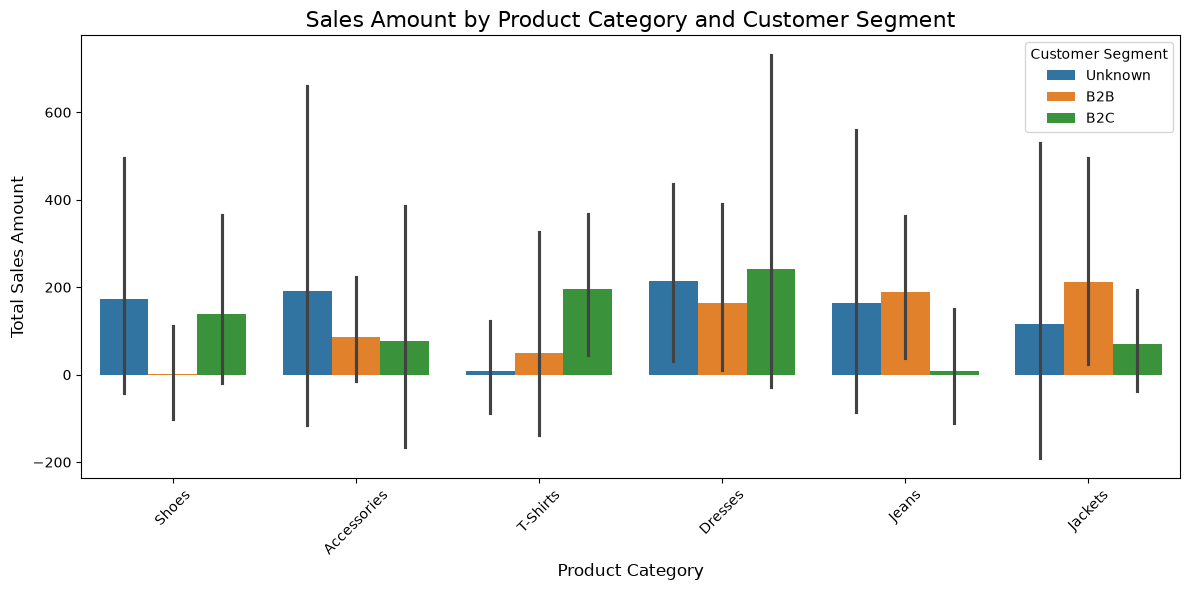

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Product_Category',
    y='Sales_Amount',
    hue='Segment',
    data=Snitch_final_data
)
plt.title('Sales Amount by Product Category and Customer Segment', fontsize=16)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Sales Amount', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Customer Segment')
plt.tight_layout()
plt.show()

ขีดสีดำของกราฟ คือ Error bars
ยิ่ง Error bars สูงก็จะหมายความว่าข้อมูลมีการกระจายตัวที่สูง มีความไม่เสถียรของชุดข้อมูล

* Shoes :
กลุ่มลูกค้า Unknown ซื้อสินค้ากลุ่มนี้ค่อนข้างมาก และมี Error bars ที่ค่อนข้างสูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอน                                                                                                                                                 
กลุ่มลูกค้า B2B ไม่แสดงในกราฟแสดงว่าอาจจะมีลูกค้าในกลุ่มนี้ซื้อสินค้าประเภทนี้น้อยมากหรืออาจจะไม่มีคนซื้อเลย                                                                                                
กลุ่มลูกค้า B2C ซื้อสินค้ากลุ่มนี้ค่อนข้างมากสูสีกับกลุ่ม Unknown และมี Error bars ที่ค่อนข้างสูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอน                                                                              

---


          

*  Accessories :
กลุ่มลูกค้า Unknown ซื้อสินค้ากลุ่มนี้ค่อนข้างมาก และมี Error bars ที่สูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอนมากๆ                                                                                                                                                
กลุ่มลูกค้า B2B ซื้อสินค้ากลุ่มนี้ค่อนข้างน้อย และมี Error bars ไม่สูง แสดงว่ายอดขายค่อนข้างสม่ำเสมอ ยอดขายนิ่งๆ ขายได้เรื่อยๆ                                                                                              
กลุ่มลูกค้า B2C ซื้อสินค้ากลุ่มนี้ค่อนข้างน้อย และมี Error bars ที่ค่อนข้างสูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอน   


---



* T-Shirts :
กลุ่มลูกค้า Unknown ซื้อสินค้ากลุ่มนี้น้อยมาก และมี Error bars ไม่สูง แสดงว่ายอดขายของกลุ่มนี้ค่อนข้างสม่ำเสมอ
ยอดขายสินค้านิ่งๆ ขายได้น้อยแบบนี้                                                                                                                                               
กลุ่มลูกค้า B2B ซื้อสินค้ากลุ่มนี้ค่อนข้างน้อย และมี Error bars ค่อนข้างสูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอนมากๆ                                                                                             
กลุ่มลูกค้า B2C ซื้อสินค้ากลุ่มนี้ค่อนข้างมาก และมี Error bars ไม่สูง แสดงว่ายอดขายของกลุ่มนี้ค่อนข้างสม่ำเสมอ สินค้ากลุ่มนี้ขายได้เยอะกับกลุ่มลูกค้า B2C   


---


*  Jeans :
กลุ่มลูกค้า Unknown ซื้อสินค้ากลุ่มนี้ค่อนข้างมาก และมี Error bars ที่สูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอนมากๆ                                                                                                                                                
กลุ่มลูกค้า B2B ซื้อสินค้ากลุ่มนี้ค่อนข้างมาก และมี Error bars ไม่สูง แสดงว่ายอดขายค่อนข้างสม่ำเสมอ  ขายได้เรื่อยๆ                                                                                              
กลุ่มลูกค้า B2C ซื้อสินค้ากลุ่มนี้น้อยมาก และมี Error bars ไม่สูง แสดงว่ายอดขายของกลุ่มนี้มีค่อนข้างสม่ำเสมอ ขายได้น้อยในลูกค้ากลุ่มนี้


---


*  Dresses :
กลุ่มลูกค้า Unknown ซื้อสินค้ากลุ่มนี้ค่อนข้างมาก และมี Error bars ไม่สูง แสดงว่ายอดขายของกลุ่มนี้ค่อนข้างสม่ำเสมอ
ยอดขายสินค้าขายได้เยอะแบบนี้เรื่อยๆ                                                                                                                                               
กลุ่มลูกค้า B2B ซื้อสินค้ากลุ่มนี้ค่อนข้างมาก และมี Error bars ไม่สูง แสดงว่ายอดขายค่อนข้างสม่ำเสมอ ยอดขายสินค้าขายได้ค่อยข้างเยอะแบบนี้เรื่อยๆ                                                                                             
กลุ่มลูกค้า B2C ซื้อสินค้ากลุ่มนี้สูง และมี Error bars ที่สูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอน   


---


*  Jackets :
กลุ่มลูกค้า Unknown ซื้อสินค้ากลุ่มนี้ค่อนข้างน้อย และมี Error bars ที่สูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอน                                                                                                                                                 
กลุ่มลูกค้า B2B ซื้อสินค้ากลุ่มนี้ค่อนข้างสูง และมี Error bars ที่สูง แสดงว่ายอดขายของกลุ่มนี้มีความผันผวน ยอดขายสินค้าไม่แน่นอน                                                                                                
กลุ่มลูกค้า B2C ซื้อสินค้ากลุ่มนี้ค่อนข้างน้อย และมี Error bars ไม่สูง แสดงว่ายอดขายของกลุ่มนี้ค่อนข้างสม่ำเสมอ ขายได้น้อยแบบนี้อย่างสม่ำเสมอ  










In [ ]:
Snitch_final_data.groupby('City')['Sales_Amount'].sum().reset_index()

,City,Sales_Amount
0,Ahmedabad,56348.91
1,Bangalore,84312.15
2,Delhi,24145.83
3,Hyd,41301.77
4,Hyderabad,26783.49
5,Mumbai,40121.51
6,Pune,40714.24
7,bengaluru,2947.02
8,hyderbad,215.71



*   Ahmedabad	= 56348.91
*   Bangalore + bengaluru = 84312.15 + 2947.02 = 87259.17

*   Delhi = 24145.83
*   Hyd + Hyderabad  = 41301.77 + 26783.49  = 68085.26

*   hyderbad = 215.71

*   Mumbai = 40121.51
*   Pune = 40714.24


---


### *  สรุปแล้วยอดขายในเมือง Bangalore สูงที่สุดจากทุกเมือง




# Correlation plot

<Axes: >

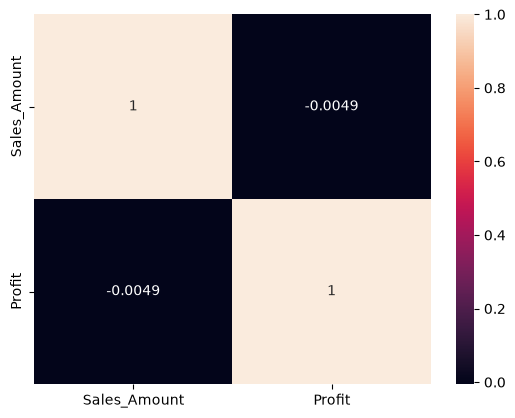

In [ ]:
corr = Snitch_final_data[['Sales_Amount','Profit']].corr()
sb.heatmap(corr , annot = True)

In [ ]:
Snitch_final_data[['Sales_Amount','Profit']].corr()

,Sales_Amount,Profit
Sales_Amount,1.000000,-0.004945
Profit,-0.004945,1.000000




*  ไม่มีความสัมพันธ์กันอย่างชัดเจน ค่า -0.0049 แสดงว่าแทบจะไม่มีความสัมพันธ์กันในเชิงเส้นสำหรับข้อมูลนี้ ความหมายของข้อมูลคือยอดขายเพิ่มขึ้น แต่ไม่ได้หมายความว่ากำไรจะเพิ่มตาม แบรนด์นี้อาจจะกำลังเจอกับสถานการณ์ที่ "ขายได้เยอะ แต่แทบจะไม่เหลือกำไร"





<Axes: >

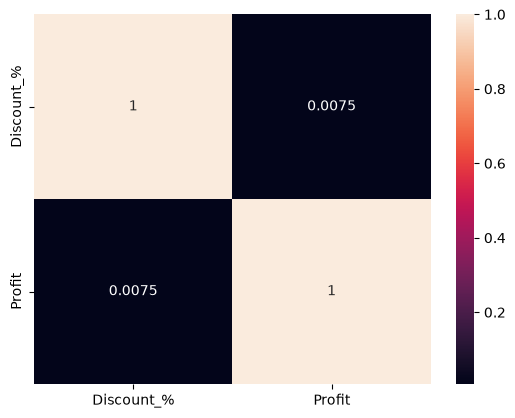

In [ ]:
corr = Snitch_final_data[['Discount_%','Profit']].corr()
sb.heatmap(corr, annot = True)

In [ ]:
Snitch_final_data[['Discount_%','Profit']].corr()

,Discount_%,Profit
Discount_%,1.00000,0.00745
Profit,0.00745,1.00000


*  ไม่มีความสัมพันธ์กันอย่างชัดเจน ค่า 0.0075 แสดงว่าแทบจะไม่มีความสัมพันธ์กันในเชิงเส้นสำหรับข้อมูลนี้ ความหมายของข้อมูลคือส่วนลดที่ทางแบรนด์มีให้ลูกค้า ไม่ส่งผลกระทบกับกำไร ส่วนลดอาจจะไม่ใช่ปัจจัยหลักในการแปรผันของกำไร

<Axes: >

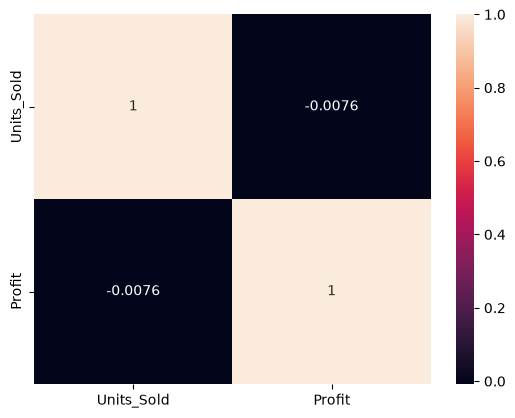

In [ ]:
corr = Snitch_final_data[['Units_Sold','Profit']].corr()
sb.heatmap(corr, annot = True)

In [ ]:
Snitch_final_data[['Units_Sold','Profit']].corr()

,Units_Sold,Profit
Units_Sold,1.000000,-0.007566
Profit,-0.007566,1.000000


*  ไม่มีความสัมพันธ์กันอย่างชัดเจน ค่า -0.01 แสดงว่าแทบจะไม่มีความสัมพันธ์กันในเชิงเส้นสำหรับข้อมูลนี้ ความหมายของข้อมูลคือ จำนวนหน่วยที่ขายได้มาก ไม่ได้ทำให้กำไรเพิ่มมากขึ้น เพราะข้อมูลบ่งบอกว่ายิ่งขายได้จำนวนมาก ส่งผลให้กำไรลดลงเล็กน้อย ซึ่งเป็นข้อมูลที่ผิดปกติที่ไม่น่าจะเกิดขึ้นสำหรับการทำธุรกิจ

In [ ]:
# คำนวณ Revenue (รายได้สุทธิ)

Snitch_final_data['Revenue'] = (
    Snitch_final_data['Units_Sold'] * Snitch_final_data['Unit_Price']
) * (1 - Snitch_final_data['Discount_%'])

# คำนวณ COGS (ต้นทุนสินค้าที่ขาย)
# COGS = Revenue - Profit
Snitch_final_data['COGS'] = Snitch_final_data['Revenue'] - Snitch_final_data['Profit']

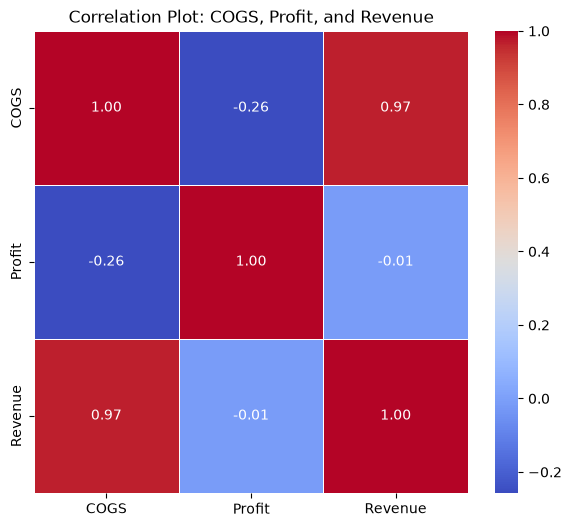

In [ ]:
data_for_corr = Snitch_final_data[['COGS', 'Profit', 'Revenue']].copy()

correlation_matrix = data_for_corr.corr()

plt.figure(figsize=(7, 6))
sb.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=.5,
)
plt.title('Correlation Plot: COGS, Profit, and Revenue')
plt.show()

In [ ]:
Snitch_final_data[['COGS','Revenue']].corr()

,COGS,Revenue
COGS,1.000000,0.969906
Revenue,0.969906,1.000000



* มีความสัมพันธ์เชิงบวก ได้ 0.97 ซึ่งสูงมาก ความหมายของข้อมูลคือถ้าขายสินค้าได้เยอะ
ก็จะได้รับรายได้เพิ่มขึ้นตามไปด้วย







In [ ]:
Snitch_final_data[['Profit','Revenue']].corr()

,Profit,Revenue
Profit,1.000000,-0.014038
Revenue,-0.014038,1.000000




* มีความสัมพันธ์เชิงลบ ได้ -0.01 ความหมายของข้อมูลคือถ้าได้รับรายได้เพิ่มขึ้น ไม่ได้แปลว่ากำไรจะเพิ่มขึ้นตามไปด้วย




In [ ]:
Snitch_final_data[['COGS','Profit']].corr()

,COGS,Profit
COGS,1.000000,-0.257073
Profit,-0.257073,1.000000




* มีความสัมพันธ์เชิงลบ ได้ -0.26 ความหมายของข้อมูลคือเมื่อต้นทุนของสินค้าเพิ่มขึ้น กำไรจะลดลง




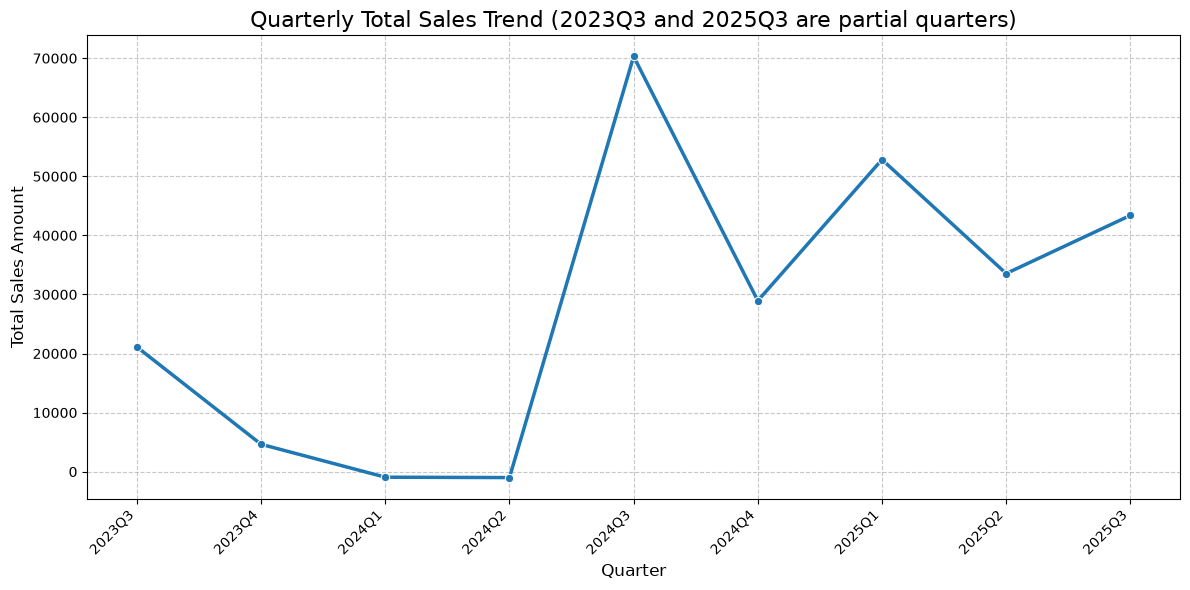

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    x='Quarter',
    y='Total_Sales',
    data=quarterly_sales,
    marker='o', # เพิ่มจุดบนเส้น
    linewidth=2.5,
    color='#1f77b4'
)

# เพิ่ม Title และ Label
plt.title('Quarterly Total Sales Trend (2023Q3 and 2025Q3 are partial quarters)', fontsize=16)
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Total Sales Amount', fontsize=12)
plt.xticks(rotation=45, ha='right') # หมุนชื่อ Quarter ให้อ่านง่าย
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

* ยอดขายรายไตรมาสผันผวนมาก (ตั้งแต่ประมาณ −1,003 ถึง 70,312) และ **ต้องอ่านอย่างระวัง** เพราะ `Sales_Amount` ส่วนใหญ่เป็น 0 (ดูเปอร์เซ็นต์จากเซลล์สรุปด้านล่าง) ยอดรวมจึงมาจากไม่กี่ออเดอร์ที่คำนวณยอดขายได้

* **2023:** ข้อมูลเริ่มวันที่ 23 ก.ค. 2023 จึงมีเพียง Q3 (ไม่ครบไตรมาส) กับ Q4 ยอดขาย 21,102 และ 4,629 ตามลำดับ (ไม่มี Q1–Q2 2023 ในข้อมูล)

---

* **2024:** Q1 และ Q2 ยอดขายรวมติดลบเล็กน้อย (−938 และ −1,003) แล้วพุ่งเป็น 70,312 ใน Q3 พร้อมกับจำนวนออเดอร์ที่เพิ่มจาก 75 เป็น 317 (ดูตารางสรุป) ก่อนลดเหลือ 28,944 ใน Q4

---

* **2025:** Q1 = 52,840, Q2 = 33,549 และ Q3 = 43,385 (เพียง 22 วัน เพราะข้อมูลสิ้นสุด 22 ก.ค.)

* สาเหตุของยอดที่ติดลบหรือพุ่งสูง (เช่น การคืนสินค้า แคมเปญ) เป็นเพียงสมมติฐาน พิสูจน์ไม่ได้จากข้อมูลนี้ ส่วนยอดติดลบเกิดจาก `Units_Sold` ติดลบหรือ `Discount_%` เกิน 100% ในข้อมูลต้นทาง
* ไม่มีข้อมูล Q4 2025 จึงไม่ควรพยากรณ์ไตรมาสถัดไปจากกราฟนี้


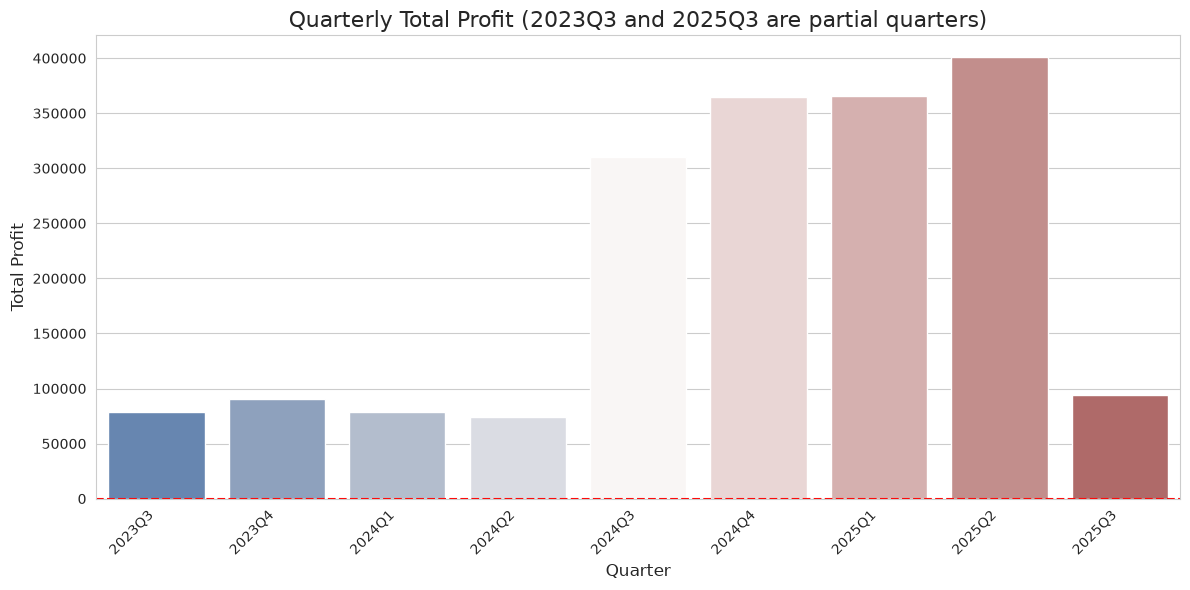

In [ ]:

sns.set_style("whitegrid")

df = Snitch_final_data.copy()


# แปลงคอลัมน์ Order_Date ให้เป็น datetime
df['Order_Date'] = pd.to_datetime(
    df['Order_Date'],
    errors='coerce',  # จัดการค่าที่แปลงไม่ได้
    format='%d-%m-%Y'
)
df = df.dropna(subset=['Order_Date'])  # ไม่นับแถวที่ไม่มีวันที่เข้าไตรมาส

df['Quarter'] = df['Order_Date'].dt.to_period('Q').astype(str)


# การรวมกำไร (Total Profit) ตาม Quarter
quarterly_profit = df.groupby('Quarter')['Profit'].sum().reset_index()
quarterly_profit.rename(columns={'Profit': 'Total_Profit'}, inplace=True)


# เรียงลำดับ Quarter ตามลำดับเวลา
quarterly_profit['Quarter_Sort'] = pd.PeriodIndex(quarterly_profit['Quarter'], freq='Q')
quarterly_profit.sort_values(by='Quarter_Sort', inplace=True)


# พล็อต Bar Chart (แสดงกำไร/ขาดทุน)
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Quarter',
    y='Total_Profit',
    data=quarterly_profit, # DataFrame นี้มีคอลัมน์ 'Quarter' แล้ว
    hue='Quarter',
    legend=False,
    palette='vlag'
)

# เพิ่มเส้นแกน X ที่ค่า 0 เพื่อเน้นจุดที่แบ่งกำไรกับขาดทุน
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)

plt.title('Quarterly Total Profit (2023Q3 and 2025Q3 are partial quarters)', fontsize=16)
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Total Profit', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

* กำไรรวมรายไตรมาสอยู่ที่ประมาณ 74,000–90,000 ในช่วง 2023 Q3 ถึง 2024 Q2 แล้วเพิ่มเป็น 309,845 ใน 2024 Q3 และอยู่ระดับ 365,000–400,000 ต่อมา (สูงสุด 2025 Q2 = 400,703)

* การกระโดดนี้ตรงกับจำนวนออเดอร์ที่เพิ่มขึ้นราว 4 เท่า ขณะที่ **กำไรต่อออเดอร์ค่อนข้างคงที่** (ประมาณ 900–1,200 ดูตารางสรุป) การเติบโตของกำไรจึงมาจากจำนวนออเดอร์ที่บันทึกในข้อมูลมากขึ้น ไม่ใช่กำไรต่อออเดอร์ที่ดีขึ้น (อาจเป็นผลจากการเก็บข้อมูลด้วย)

* 2025 Q3 ยังไม่ครบไตรมาส (22 วัน) กำไรรวม 94,249 ไม่ควรเทียบกับ Q2 ตรงๆ ต้องเทียบเป็นต่อวัน (ดูสรุปด้านล่าง)


In [ ]:
# ตารางสรุปรายไตรมาส (คำนวณจากข้อมูล) เทียบแบบ "ต่อวัน" เพราะ Q3 2023 และ Q3 2025 มีข้อมูลไม่ครบไตรมาส
first_date, last_date = dated['Order_Date'].min(), dated['Order_Date'].max()

summary = quarterly_sales.merge(quarterly_profit[['Quarter', 'Total_Profit']], on='Quarter')
summary['Period'] = pd.PeriodIndex(summary['Quarter'], freq='Q')
summary = summary.sort_values('Period').reset_index(drop=True)

summary['Orders'] = summary['Quarter'].map(dated.groupby('Quarter').size())
summary['Days_Covered'] = [
    (min(p.end_time.normalize(), last_date) - max(p.start_time, first_date)).days + 1
    for p in summary['Period']
]
summary['Profit_per_order'] = summary['Total_Profit'] / summary['Orders']
summary['Sales_per_day'] = summary['Total_Sales'] / summary['Days_Covered']
summary['Profit_per_day'] = summary['Total_Profit'] / summary['Days_Covered']

# คุณภาพของ Sales_Amount (ใช้ประกอบการอ่านยอดขาย)
sa = Snitch_dropdup['Sales_Amount']
print(f"Sales_Amount = 0: {(sa == 0).mean():.1%} ของแถว | แถวที่ไม่ใช่ 0: {(sa != 0).sum()} แถว | ติดลบ: {(sa < 0).sum()} แถว")
print()

last_q, prev_q = summary.iloc[-1], summary.iloc[-2]
print(f"วันที่ล่าสุดในข้อมูล: {last_date.date()} -> {last_q['Quarter']} มีข้อมูล {last_q['Days_Covered']} วัน ({last_q['Orders']} ออเดอร์)")
for col, name in [('Total_Sales', 'ยอดขายรวม'), ('Total_Profit', 'กำไรรวม')]:
    print(f"{name}: {prev_q['Quarter']} = {prev_q[col]:,.0f} -> {last_q['Quarter']} = {last_q[col]:,.0f}")
for col, name in [('Sales_per_day', 'ยอดขายต่อวัน'), ('Profit_per_day', 'กำไรต่อวัน')]:
    chg = (last_q[col] - prev_q[col]) / abs(prev_q[col]) * 100
    print(f"{name}: {prev_q[col]:,.0f} -> {last_q[col]:,.0f} ({chg:+.1f}%)")

summary[['Quarter', 'Orders', 'Days_Covered', 'Total_Sales', 'Total_Profit', 'Profit_per_order', 'Sales_per_day', 'Profit_per_day']].round(2)

Sales_Amount = 0: 92.8% ของแถว | แถวที่ไม่ใช่ 0: 179 แถว | ติดลบ: 70 แถว

วันที่ล่าสุดในข้อมูล: 2025-07-22 -> 2025Q3 มีข้อมูล 22 วัน (99 ออเดอร์)
ยอดขายรวม: 2025Q2 = 33,549 -> 2025Q3 = 43,385
กำไรรวม: 2025Q2 = 400,703 -> 2025Q3 = 94,249
ยอดขายต่อวัน: 369 -> 1,972 (+434.9%)
กำไรต่อวัน: 4,403 -> 4,284 (-2.7%)


,Quarter,Orders,Days_Covered,Total_Sales,Total_Profit,Profit_per_order,Sales_per_day,Profit_per_day
0,2023Q3,71,70,21102.49,78330.88,1103.25,301.46,1119.01
1,2023Q4,74,92,4629.33,90220.73,1219.20,50.32,980.66
2,2024Q1,80,91,-937.93,78787.27,984.84,-10.31,865.79
3,2024Q2,75,91,-1002.61,74347.96,991.31,-11.02,817.01
4,2024Q3,317,92,70311.83,309845.15,977.43,764.26,3367.88
5,2024Q4,382,92,28943.64,364715.12,954.75,314.60,3964.29
6,2025Q1,401,90,52840.38,365351.26,911.10,587.12,4059.46
7,2025Q2,395,91,33549.09,400702.69,1014.44,368.67,4403.33
8,2025Q3,99,22,43384.55,94249.26,952.01,1972.02,4284.06


**สรุปได้ดังนี้**

---

* ข้อมูลสิ้นสุดวันที่ 22 ก.ค. 2025 ไตรมาสล่าสุดจึงเป็น **Q3 2025 (22 วัน, 99 ออเดอร์)** ไม่มีข้อมูล Q4 2025

* ยอดขายรวม : Q2 2025 = 33,549 --> Q3 2025 = 43,385 (ต่อวัน 369 --> 1,972) แต่ไม่ควรสรุปว่ายอดขายดีขึ้น เพราะ Q3 มีข้อมูลเพียง 22 วัน และ `Sales_Amount` ส่วนใหญ่เป็น 0 ทำให้ยอดรวมขึ้นกับไม่กี่ออเดอร์

* กำไรรวม : Q2 2025 = 400,703 --> Q3 2025 = 94,249 (ลดลงเพราะไตรมาสยังไม่ครบ) แต่ต่อวัน 4,403 --> 4,284 (ลดลงราว 2.7%) จึงถือว่ากำไรต่อวันใกล้เคียงเดิม

* กำไรไม่สัมพันธ์กับยอดขาย จำนวนที่ขาย หรือส่วนลด (|r| ต่ำกว่า 0.02 ในทุกคู่) ยอดขายที่สูงขึ้นจึงไม่ได้แปลว่ากำไรสูงขึ้น และข้อมูลนี้ไม่ได้บอกว่าส่วนลดหรือต้นทุนเป็นสาเหตุของกำไร

* หมายเหตุ: ข้อมูลน่าจะเป็นข้อมูลสังเคราะห์จาก Kaggle ผลที่ได้ใช้เพื่อฝึกวิเคราะห์ ไม่ใช่ข้อสรุปของธุรกิจจริง
